# Análisis de la contratación pública — SECOP II

Fuente: **SECOP II – Contratos Electrónicos** (`jbjy-vk9h`), Colombia Compra Eficiente, publicado en datos.gov.co con actualización diaria.

El notebook trabaja en dos niveles:

1. **Panorama nacional calculado en el servidor.** Los conteos y sumas por mes, departamento, modalidad y tipo se piden ya agregados a la API, así que cubren *todos* los contratos del periodo sin descargar millones de filas.
2. **Análisis detallado de un territorio.** Se descargan los contratos del departamento elegido para estudiar entidades, proveedores, concentración, plazos, adiciones, ejecución y señales de alerta.

Solo cambia la celda de **parámetros** y ejecuta todo.

In [1]:
%pip install -q requests pandas pyarrow matplotlib openpyxl

## 1. Parámetros

In [2]:
FECHA_INI    = "2024-01-01"   # fecha de firma desde
FECHA_FIN    = "2025-12-31"   # fecha de firma hasta
DEPARTAMENTO = "Meta"         # tal como aparece en SECOP (ver tabla de la sección 3). None = todo el país (millones de filas)
MAX_FILAS    = None           # p. ej. 50_000 para una prueba rápida; None = todo lo que cumpla el filtro
USAR_CACHE   = True           # reutiliza la descarga guardada si ya existe con los mismos parámetros

# Umbrales de las señales de alerta (sección 6)
MIN_CONTRATOS_RECURRENTE = 10   # contratos de un mismo proveedor con una misma entidad en un año
MIN_CONTRATOS_ENTIDAD    = 30   # mínimo de contratos para calcular concentración por entidad

## 2. Cliente de la API y utilidades

In [3]:
import os, re, time, unicodedata, requests, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)

DATA = Path("data_secop"); DATA.mkdir(exist_ok=True)
SECOP_ID = "jbjy-vk9h"
BASE = "https://www.datos.gov.co/resource/{}.json"
TOKEN = os.getenv("SOCRATA_APP_TOKEN")              # os.environ["SOCRATA_APP_TOKEN"] = "tu_token"
HEADERS = {"X-App-Token": TOKEN} if TOKEN else {}

def socrata(dataset_id, select=None, where=None, group=None, order=None,
            limit=50000, max_rows=None, timeout=300, reintentos=3):
    # Descarga paginada con reintentos desde datos.gov.co (API Socrata / SoQL)
    params = {"$limit": limit}
    if select: params["$select"] = select
    if where:  params["$where"]  = where
    if group:  params["$group"]  = group
    params["$order"] = order or (group if group else ":id")
    frames, offset = [], 0
    while True:
        params["$offset"] = offset
        for intento in range(reintentos):
            try:
                r = requests.get(BASE.format(dataset_id), params=params, headers=HEADERS, timeout=timeout)
                r.raise_for_status()
                break
            except requests.RequestException as e:
                if intento == reintentos - 1:
                    raise
                print(f"  reintento {intento + 1}: {e}")
                time.sleep(5 * (intento + 1))
        batch = r.json()
        if not batch:
            break
        frames.append(pd.DataFrame(batch))
        offset += len(batch)
        print(f"  {dataset_id}: {offset:,} filas", end="\r")
        if len(batch) < limit or (max_rows and offset >= max_rows):
            break
        time.sleep(0.3)
    print()
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def filtro(departamento=None, fecha_ini=FECHA_INI, fecha_fin=FECHA_FIN, extra=None):
    # Construye el $where común: periodo de firma, valor positivo y (opcional) departamento
    w = [f"fecha_de_firma between '{fecha_ini}T00:00:00' and '{fecha_fin}T23:59:59'",
         "valor_del_contrato > 0"]
    if departamento:
        w.append("departamento = '{}'".format(departamento.replace("'", "''")))
    if extra:
        w.append(extra)
    return " AND ".join(w)

DIMENSIONES = {"mes": "date_trunc_ym(fecha_de_firma) as mes",
               "anio": "date_extract_y(fecha_de_firma) as anio"}

def agregado(por, where):
    # Conteo y suma de valor agrupados EN EL SERVIDOR (no descarga contratos individuales)
    por = [por] if isinstance(por, str) else list(por)
    sel = ", ".join(DIMENSIONES.get(p, p) for p in por)
    df = socrata(SECOP_ID,
                 select=f"{sel}, count(*) as n_contratos, sum(valor_del_contrato) as valor_total",
                 where=where, group=", ".join(por))
    if df.empty:
        return df
    df["n_contratos"] = pd.to_numeric(df["n_contratos"])
    df["valor_total"] = pd.to_numeric(df["valor_total"])
    if "mes" in df:
        df["mes"] = pd.to_datetime(df["mes"])
        return df.sort_values("mes").reset_index(drop=True)
    df["pct_contratos"] = df["n_contratos"] / df["n_contratos"].sum() * 100
    df["pct_valor"] = df["valor_total"] / df["valor_total"].sum() * 100
    return df.sort_values("valor_total", ascending=False).reset_index(drop=True)

In [4]:
# Formato de pesos y estilo de los gráficos
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "font.size": 9.5,
    "legend.frameon": False, "axes.axisbelow": True,
})

def _es(texto):
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")

def cop(x):
    # 1.234.567.890 -> "$1,2 mil millones"
    if pd.isna(x): return "—"
    a = abs(x)
    if a >= 1e12: t = f"{x/1e12:,.2f} billones"
    elif a >= 1e9: t = f"{x/1e9:,.1f} mil millones"
    elif a >= 1e6: t = f"{x/1e6:,.1f} millones"
    else: t = f"{x:,.0f}"
    return "$" + _es(t)

def cop_corto(x, _=None):
    a = abs(x)
    if a >= 1e12: return _es(f"${x/1e12:,.1f} B")
    if a >= 1e9:  return _es(f"${x/1e9:,.0f} MM")
    if a >= 1e6:  return _es(f"${x/1e6:,.0f} M")
    return _es(f"${x:,.0f}")

def entero(x, _=None):
    return _es(f"{x:,.0f}")

def pct(x, _=None):
    return _es(f"{x:.1f} %")

def corto(t, n=48):
    t = str(t)
    return t if len(t) <= n else t[:n - 1] + "…"

def barras(serie, titulo, fmt=cop_corto, resaltar=None, top=15, color=AZUL):
    # Barras horizontales ordenadas, con etiqueta de valor al final de cada barra
    s = serie.head(top)[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.36 * len(s) + 1.1))
    colores = [NARANJA if resaltar is not None and k == resaltar else color for k in s.index]
    ax.barh([corto(k) for k in s.index], s.values, color=colores, height=0.68)
    for y, v in enumerate(s.values):
        ax.text(v, y, "  " + fmt(v), va="center", fontsize=8.5, color=TINTA2)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(fmt))
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, s.max() * 1.18)
    ax.set_title(titulo)
    plt.tight_layout(); plt.show()

def numero_vs_valor(tabla, etiqueta, titulo, top=10):
    # Compara la participación de cada categoría en el NÚMERO de contratos y en el VALOR
    t = tabla.head(top).iloc[::-1]
    y = np.arange(len(t)); h = 0.38
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(t) + 1.2))
    ax.barh(y + h/2, t["pct_contratos"], h, color=AZUL, label="% del número de contratos")
    ax.barh(y - h/2, t["pct_valor"], h, color=NARANJA, label="% del valor contratado")
    ax.set_yticks(y, [corto(v) for v in t[etiqueta]])
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
    ax.legend(loc="upper left", bbox_to_anchor=(0, -0.10), ncol=2)
    ax.set_title(titulo)
    plt.tight_layout(); plt.show()

def resumen_por(df, col):
    # Tabla de número, valor y participación por una columna del detalle
    t = (df.groupby(col, dropna=False)
           .agg(n_contratos=("id_contrato", "size"), valor_total=("valor_del_contrato", "sum"),
                valor_mediano=("valor_del_contrato", "median"))
           .sort_values("valor_total", ascending=False))
    t["pct_contratos"] = t["n_contratos"] / t["n_contratos"].sum() * 100
    t["pct_valor"] = t["valor_total"] / t["valor_total"].sum() * 100
    return t.reset_index()

def mostrar(df, pesos=(), pct=()):
    # Muestra una tabla con pesos y porcentajes legibles
    fmt = {c: cop for c in pesos}
    fmt.update({c: (lambda v: _es(f"{v:.1f} %")) for c in pct})
    fmt.update({c: entero for c in df.select_dtypes("number").columns if c not in fmt})
    return df.style.format(fmt, na_rep="—").hide(axis="index")

## 3. Panorama nacional (agregado en el servidor)

Estas consultas suman todos los contratos firmados en el periodo, en todo el país. Tardan segundos porque la API devuelve solo los totales.

In [5]:
W_PAIS = filtro()                       # todo el país
nac_mes  = agregado("mes", W_PAIS)
nac_dep  = agregado("departamento", W_PAIS)
nac_mod  = agregado("modalidad_de_contratacion", W_PAIS)
nac_tipo = agregado("tipo_de_contrato", W_PAIS)
nac_orden = agregado("orden", W_PAIS)

tot_n, tot_v = nac_mes["n_contratos"].sum(), nac_mes["valor_total"].sum()
print(f"Periodo {FECHA_INI} a {FECHA_FIN}: {entero(tot_n)} contratos por {cop(tot_v)}")
mostrar(nac_dep, pesos=["valor_total"], pct=["pct_contratos", "pct_valor"])

  jbjy-vk9h: 24 filas
  jbjy-vk9h: 34 filas
  jbjy-vk9h: 15 filas
  jbjy-vk9h: 23 filas
  jbjy-vk9h: 4 filas
Periodo 2024-01-01 a 2025-12-31: 1.885.702 contratos por $7.766,11 billones


departamento,n_contratos,valor_total,pct_contratos,pct_valor
No Definido,35.882,"$6.457,79 billones","1,9 %","83,2 %"
Nariño,31.511,"$947,07 billones","1,7 %","12,2 %"
Distrito Capital de Bogotá,546.714,"$128,71 billones","29,0 %","1,7 %"
Chocó,6.953,"$64,11 billones","0,4 %","0,8 %"
Antioquia,190.498,"$42,62 billones","10,1 %","0,5 %"
Valle del Cauca,196.032,"$17,48 billones","10,4 %","0,2 %"
Atlántico,58.155,"$10,87 billones","3,1 %","0,1 %"
Bolívar,61.151,"$10,39 billones","3,2 %","0,1 %"
Cundinamarca,96.945,"$9,24 billones","5,1 %","0,1 %"
Boyacá,59.779,"$8,95 billones","3,2 %","0,1 %"


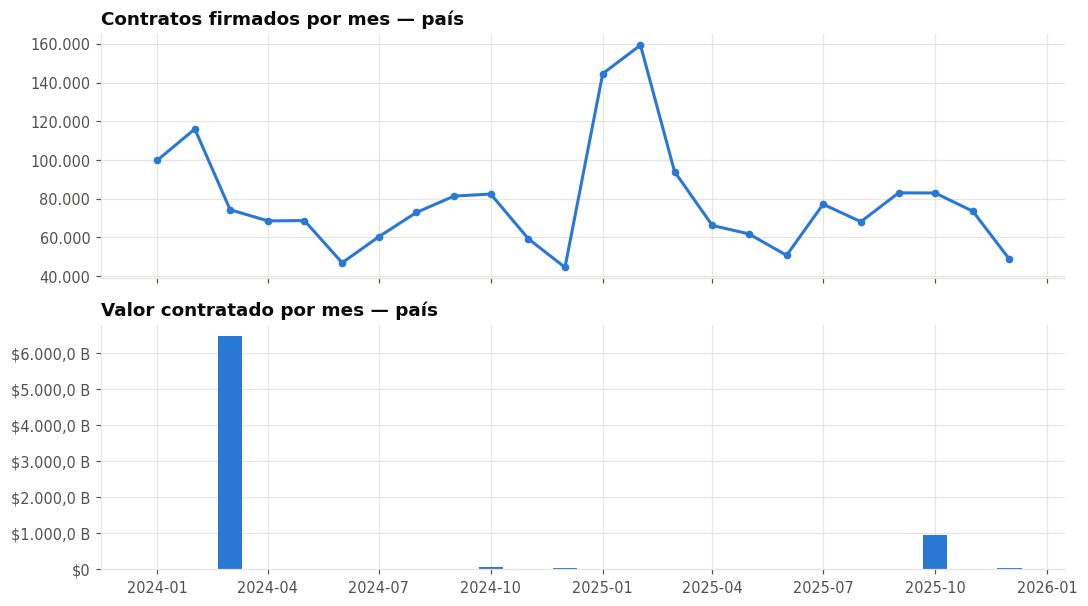

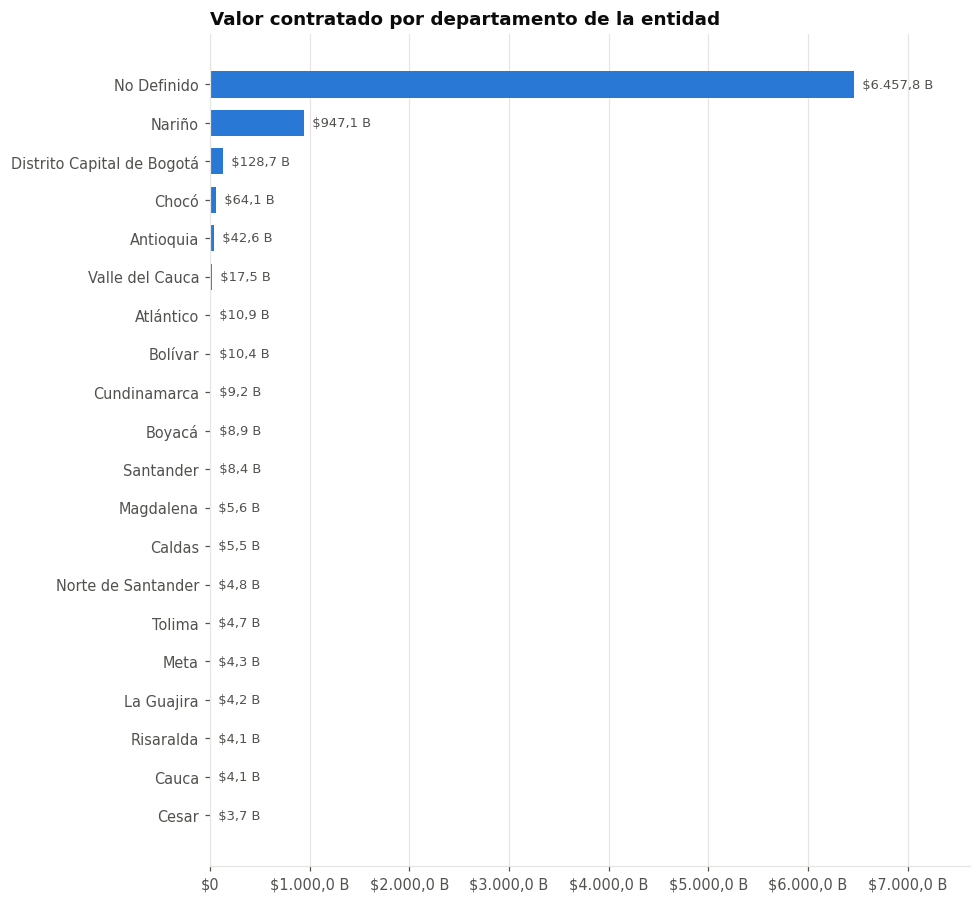

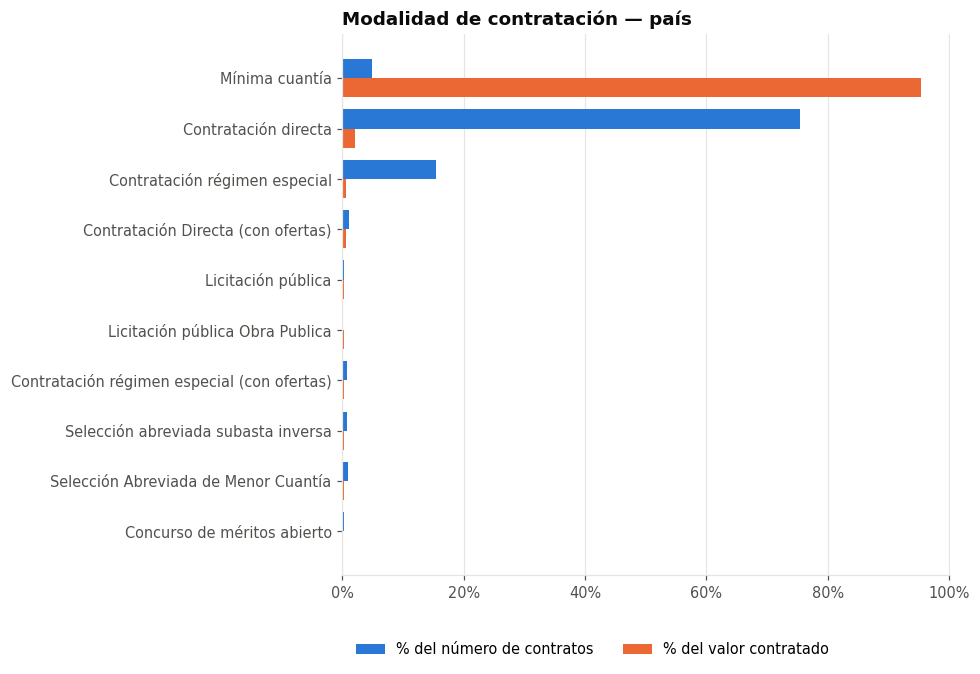

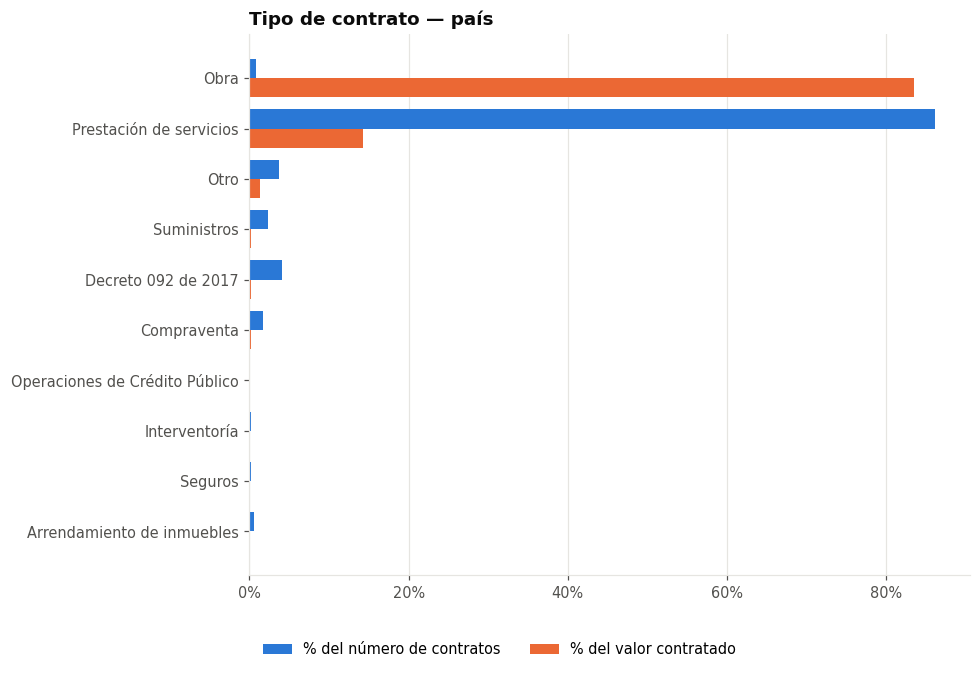

In [6]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True)
a1.plot(nac_mes["mes"], nac_mes["n_contratos"], color=AZUL, lw=2, marker="o", ms=4)
a1.set_title("Contratos firmados por mes — país")
a1.yaxis.set_major_formatter(mtick.FuncFormatter(entero))
a2.bar(nac_mes["mes"], nac_mes["valor_total"], width=20, color=AZUL)
a2.set_title("Valor contratado por mes — país")
a2.yaxis.set_major_formatter(mtick.FuncFormatter(cop_corto))
plt.tight_layout(); plt.show()

barras(nac_dep.set_index("departamento")["valor_total"],
       "Valor contratado por departamento de la entidad", resaltar=DEPARTAMENTO, top=20)
numero_vs_valor(nac_mod, "modalidad_de_contratacion", "Modalidad de contratación — país")
numero_vs_valor(nac_tipo, "tipo_de_contrato", "Tipo de contrato — país")

## 4. Descarga detallada del territorio

Se excluyen a propósito las columnas con datos personales (representantes legales, ordenadores del gasto, supervisores y cuentas bancarias): no hacen falta para el análisis.

In [7]:
COLS = [
    "id_contrato", "proceso_de_compra", "nombre_entidad", "nit_entidad", "codigo_entidad",
    "departamento", "ciudad", "orden", "sector", "rama", "entidad_centralizada", "estado_contrato",
    "codigo_de_categoria_principal", "objeto_del_contrato", "tipo_de_contrato",
    "modalidad_de_contratacion", "justificacion_modalidad_de",
    "fecha_de_firma", "fecha_de_inicio_del_contrato", "fecha_de_fin_del_contrato", "duraci_n_del_contrato",
    "documento_proveedor", "proveedor_adjudicado", "es_grupo", "es_pyme",
    "origen_de_los_recursos", "destino_gasto", "espostconflicto", "liquidaci_n",
    "valor_del_contrato", "valor_facturado", "valor_pagado", "valor_pendiente_de_ejecucion",
    "dias_adicionados", "urlproceso", "ultima_actualizacion",
]

etiqueta = (DEPARTAMENTO or "pais").lower().replace(" ", "_")
RUTA_CRUDO = DATA / f"secop_{etiqueta}_{FECHA_INI}_{FECHA_FIN}_{MAX_FILAS or 'todo'}.parquet"

if USAR_CACHE and RUTA_CRUDO.exists():
    crudo = pd.read_parquet(RUTA_CRUDO)
    print(f"Leído de caché: {RUTA_CRUDO} ({entero(len(crudo))} filas)")
else:
    crudo = socrata(SECOP_ID, select=", ".join(COLS), where=filtro(DEPARTAMENTO),
                    order="fecha_de_firma, :id", max_rows=MAX_FILAS)
    if "urlproceso" in crudo:   # la API entrega la URL como diccionario {"url": ...}
        crudo["urlproceso"] = crudo["urlproceso"].map(lambda u: u.get("url") if isinstance(u, dict) else u)
    crudo.to_parquet(RUTA_CRUDO, index=False)
    print(f"Descargados {entero(len(crudo))} contratos → {RUTA_CRUDO}")

  jbjy-vk9h: 45,554 filas
Descargados 45.554 contratos → data_secop/secop_meta_2024-01-01_2025-12-31_todo.parquet


## 5. Limpieza y variables derivadas

In [8]:
SEGMENTOS_UNSPSC = {
    "10": "Animales y plantas vivos", "11": "Minerales y textiles", "12": "Químicos",
    "14": "Papel", "15": "Combustibles y lubricantes", "20": "Maquinaria minera",
    "21": "Maquinaria agrícola", "22": "Maquinaria de construcción", "23": "Maquinaria industrial",
    "24": "Manejo de materiales", "25": "Vehículos", "26": "Generación de energía",
    "27": "Herramientas", "30": "Componentes de construcción", "31": "Componentes de manufactura",
    "32": "Componentes electrónicos", "39": "Iluminación y eléctricos", "40": "Distribución y acondicionamiento",
    "41": "Equipo de laboratorio", "42": "Equipo médico", "43": "TIC y telecomunicaciones",
    "44": "Equipos de oficina", "45": "Impresión, foto y audio", "46": "Defensa y seguridad",
    "47": "Limpieza", "48": "Maquinaria para servicios", "49": "Deportes y recreación",
    "50": "Alimentos y bebidas", "51": "Medicamentos", "52": "Electrodomésticos",
    "53": "Ropa y calzado", "55": "Publicaciones", "56": "Muebles",
    "60": "Material educativo y artístico", "70": "Servicios agropecuarios y forestales",
    "71": "Servicios de minería y petróleo", "72": "Construcción y mantenimiento",
    "73": "Servicios de producción industrial", "76": "Aseo industrial", "77": "Servicios ambientales",
    "78": "Transporte y almacenamiento", "80": "Gestión y servicios administrativos",
    "81": "Ingeniería, investigación y tecnología", "82": "Diseño y artes gráficas",
    "83": "Servicios públicos", "84": "Servicios financieros y seguros", "85": "Salud",
    "86": "Educación y formación", "90": "Viajes, alimentación y eventos",
    "91": "Servicios personales y domésticos", "92": "Orden público y seguridad",
    "93": "Servicios políticos y cívicos", "94": "Organizaciones y clubes", "95": "Terrenos y edificios",
}
FECHAS = ["fecha_de_firma", "fecha_de_inicio_del_contrato", "fecha_de_fin_del_contrato", "ultima_actualizacion"]
NUMERICAS = ["valor_del_contrato", "valor_facturado", "valor_pagado",
             "valor_pendiente_de_ejecucion", "dias_adicionados"]
SI_NO = ["es_pyme", "es_grupo", "espostconflicto", "liquidaci_n"]
TEXTO = ["nombre_entidad", "departamento", "ciudad", "orden", "sector", "rama", "estado_contrato",
         "tipo_de_contrato", "modalidad_de_contratacion", "justificacion_modalidad_de",
         "proveedor_adjudicado", "origen_de_los_recursos", "destino_gasto", "objeto_del_contrato"]

def sin_tildes(s):
    return s.fillna("").map(lambda t: unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode()).str.lower()

def dias_desde_texto(s):
    # "145 Dia(s)", "6 Mes(es)", "1 Año(s)" -> días
    m = s.fillna("").str.extract(r"(\d+(?:[.,]\d+)?)\s*([^\d\s(]+)")
    num = pd.to_numeric(m[0].str.replace(",", "."), errors="coerce")
    unidad = sin_tildes(m[1]).str[:3]
    return num * unidad.map({"dia": 1, "sem": 7, "mes": 30.4, "ano": 365, "hor": 1 / 24})

def preparar(raw):
    df = raw.drop_duplicates("id_contrato").copy()
    for c in FECHAS:
        df[c] = pd.to_datetime(df[c], errors="coerce")
    for c in NUMERICAS:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    for c in TEXTO:
        df[c] = df[c].astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    for c in SI_NO:
        df[c] = sin_tildes(df[c]).str.strip().map({"si": True, "no": False})

    df["anio"] = df["fecha_de_firma"].dt.year
    df["mes"] = df["fecha_de_firma"].dt.to_period("M").dt.to_timestamp()
    df["duracion_dias"] = (df["fecha_de_fin_del_contrato"] - df["fecha_de_inicio_del_contrato"]).dt.days
    df["duracion_declarada_dias"] = dias_desde_texto(df["duraci_n_del_contrato"])
    df["log_valor"] = np.log10(df["valor_del_contrato"].where(df["valor_del_contrato"] > 0))

    cod = df["codigo_de_categoria_principal"].fillna("").str.extract(r"(\d{2,8})")[0]
    df["unspsc_segmento"] = cod.str[:2]
    df["unspsc_familia"] = cod.str[:4]
    df["segmento"] = df["unspsc_segmento"].map(SEGMENTOS_UNSPSC).fillna(("Segmento " + df["unspsc_segmento"]).fillna("Sin código"))

    df["es_directa"] = df["modalidad_de_contratacion"].str.contains("directa", case=False, na=False)
    df["pct_pagado"] = (df["valor_pagado"] / df["valor_del_contrato"]).clip(0, 1.5)
    df["tiene_adicion"] = df["dias_adicionados"].fillna(0) > 0
    doc = df["documento_proveedor"].fillna("").str.replace(r"\D", "", regex=True).replace("", pd.NA)
    df["proveedor_id"] = doc.fillna(df["proveedor_adjudicado"].str.upper())
    df["objeto_norm"] = sin_tildes(df["objeto_del_contrato"])

    # Banderas de calidad del registro (no son irregularidades, son datos que conviene revisar)
    df["q_fin_antes_de_inicio"] = df["fecha_de_fin_del_contrato"] < df["fecha_de_inicio_del_contrato"]
    df["q_inicio_antes_de_firma"] = df["fecha_de_inicio_del_contrato"] < df["fecha_de_firma"] - pd.Timedelta(days=30)
    df["q_duracion_mayor_10_anios"] = df["duracion_dias"] > 3650
    df["q_sin_proveedor"] = df["proveedor_id"].isna()
    df["q_departamento_no_definido"] = df["departamento"].eq("No Definido")
    return df

det = preparar(crudo)
det.to_parquet(RUTA_CRUDO.with_name(RUTA_CRUDO.stem + "_limpio.parquet"), index=False)
print(f"{entero(len(det))} contratos únicos | {entero(det['nombre_entidad'].nunique())} entidades | "
      f"{entero(det['proveedor_id'].nunique())} proveedores | {cop(det['valor_del_contrato'].sum())}")

45.554 contratos únicos | 84 entidades | 18.100 proveedores | $4,32 billones


In [9]:
# Calidad de los datos: faltantes en columnas clave y banderas
clave = ["fecha_de_firma", "fecha_de_inicio_del_contrato", "fecha_de_fin_del_contrato",
         "valor_del_contrato", "proveedor_adjudicado", "codigo_de_categoria_principal",
         "modalidad_de_contratacion", "objeto_del_contrato"]
calidad = pd.DataFrame({"pct_faltante": det[clave].isna().mean() * 100})
banderas = det.filter(like="q_").mean().mul(100).rename("pct_registros").to_frame()
display(calidad.style.format("{:.2f} %"), banderas.style.format("{:.2f} %"))

,pct_faltante
fecha_de_firma,0.00 %
fecha_de_inicio_del_contrato,0.18 %
fecha_de_fin_del_contrato,0.00 %
valor_del_contrato,0.00 %
proveedor_adjudicado,0.00 %
codigo_de_categoria_principal,0.00 %
modalidad_de_contratacion,0.00 %
objeto_del_contrato,0.00 %


,pct_registros
q_fin_antes_de_inicio,0.04 %
q_inicio_antes_de_firma,0.04 %
q_duracion_mayor_10_anios,0.01 %
q_sin_proveedor,0.00 %
q_departamento_no_definido,0.00 %


## 6. Análisis del territorio

### 6.1 ¿De qué tamaño son los contratos?

Percentiles del valor: p10: $5,3 millones | p25: $9,0 millones | p50: $15,8 millones | p75: $28,0 millones | p90: $55,0 millones | p99: $1,3 mil millones
El 1 % de contratos más grandes concentra el 60,9 % del valor.


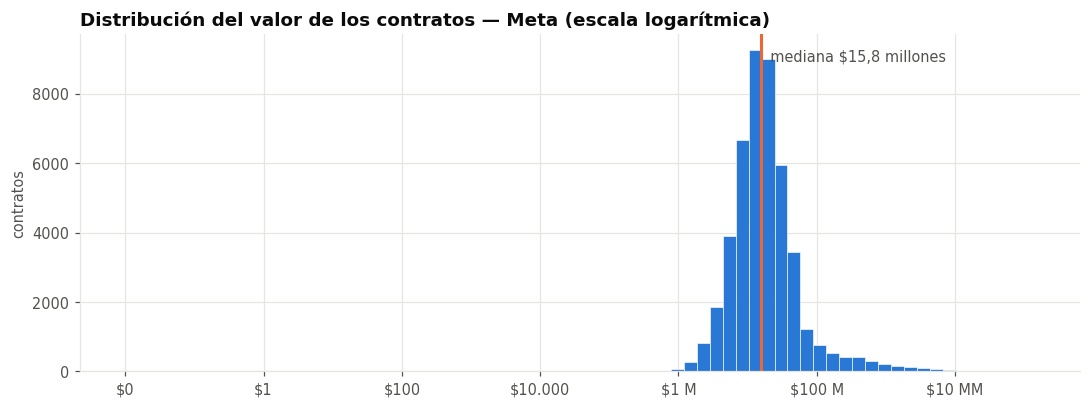

In [10]:
v = det["valor_del_contrato"]
perc = v.quantile([.10, .25, .50, .75, .90, .99]).rename(lambda q: f"p{int(q*100)}")
print("Percentiles del valor:", " | ".join(f"{k}: {cop(x)}" for k, x in perc.items()))
top1 = v.sort_values(ascending=False).head(max(1, len(v) // 100)).sum() / v.sum() * 100
print(f"El 1 % de contratos más grandes concentra el {pct(top1)} del valor.")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(det["log_valor"].dropna(), bins=70, color=AZUL, edgecolor="white", linewidth=0.4)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: cop_corto(10 ** x)))
ax.axvline(np.log10(perc["p50"]), color=NARANJA, lw=2)
ax.text(np.log10(perc["p50"]), ax.get_ylim()[1] * .92, "  mediana " + cop(perc["p50"]), color=TINTA2)
ax.set_title(f"Distribución del valor de los contratos — {DEPARTAMENTO or 'país'} (escala logarítmica)")
ax.set_ylabel("contratos")
plt.tight_layout(); plt.show()

### 6.2 Evolución en el tiempo

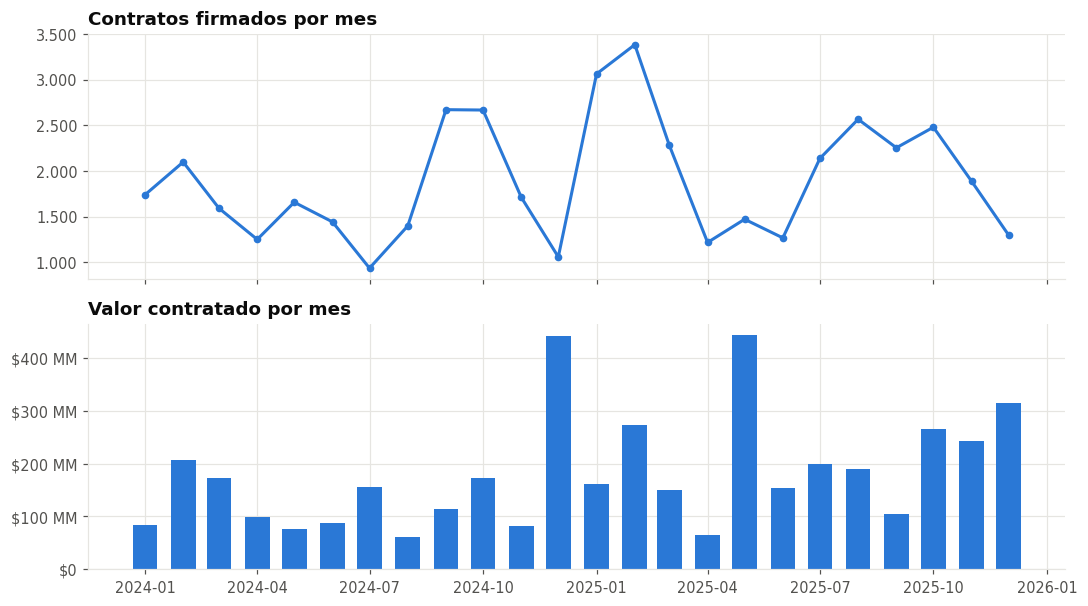

Participación por mes del año: 1: 10,5 % | 2: 12,0 % | 3: 8,5 % | 4: 5,4 % | 5: 6,9 % | 6: 6,0 % | 7: 6,8 % | 8: 8,7 % | 9: 10,8 % | 10: 11,3 % | 11: 7,9 % | 12: 5,2 %


In [11]:
por_mes = det.groupby("mes").agg(n=("id_contrato", "size"), valor=("valor_del_contrato", "sum"))
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True)
a1.plot(por_mes.index, por_mes["n"], color=AZUL, lw=2, marker="o", ms=4)
a1.set_title("Contratos firmados por mes")
a1.yaxis.set_major_formatter(mtick.FuncFormatter(entero))
a2.bar(por_mes.index, por_mes["valor"], width=20, color=AZUL)
a2.set_title("Valor contratado por mes")
a2.yaxis.set_major_formatter(mtick.FuncFormatter(cop_corto))
plt.tight_layout(); plt.show()

# Estacionalidad: ¿en qué mes del año se firma más?
estac = det.groupby(det["fecha_de_firma"].dt.month)["id_contrato"].size()
estac = estac / estac.sum() * 100
print("Participación por mes del año:", " | ".join(f"{m}: {pct(p)}" for m, p in estac.items()))

### 6.3 Cómo se contrata: modalidad y tipo

Contratación directa: 65,4 % de los contratos y 33,9 % del valor


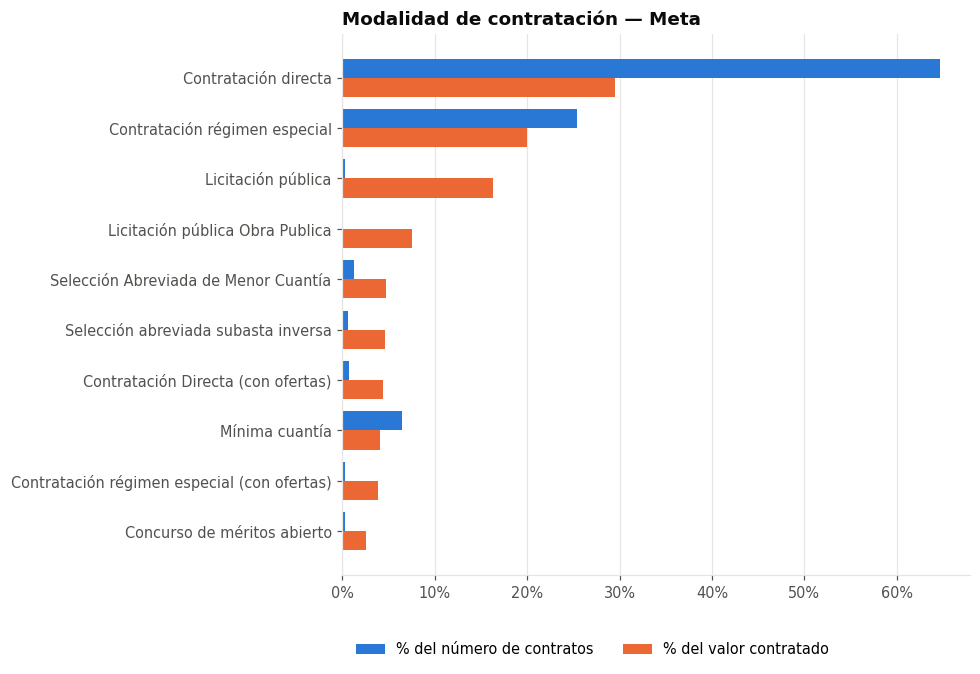

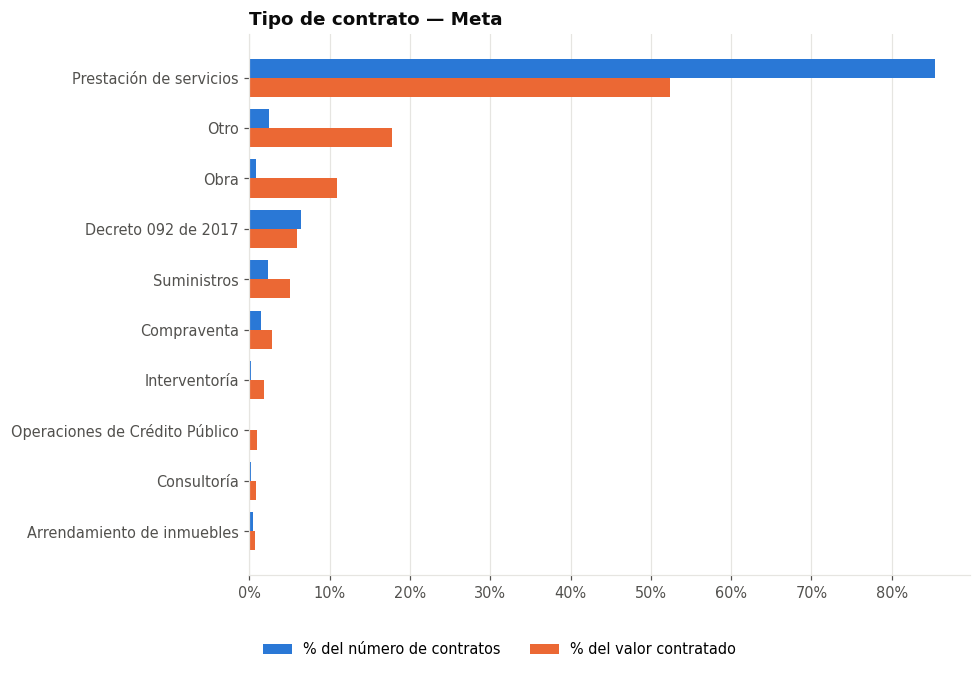

modalidad_de_contratacion,n_contratos,valor_total,valor_mediano,pct_contratos,pct_valor
Contratación directa,29.454,"$1,28 billones","$15,9 millones","64,7 %","29,6 %"
Contratación régimen especial,11.575,"$860,4 mil millones","$12,0 millones","25,4 %","19,9 %"
Licitación pública,110,"$703,1 mil millones","$2,8 mil millones","0,2 %","16,3 %"
Licitación pública Obra Publica,40,"$326,1 mil millones","$2,3 mil millones","0,1 %","7,6 %"
Selección Abreviada de Menor Cuantía,549,"$203,1 mil millones","$257,6 millones","1,2 %","4,7 %"
Selección abreviada subasta inversa,294,"$200,9 mil millones","$279,3 millones","0,6 %","4,7 %"
Contratación Directa (con ofertas),324,"$187,7 mil millones","$99,2 millones","0,7 %","4,3 %"
Mínima cuantía,2.935,"$177,2 mil millones","$30,0 millones","6,4 %","4,1 %"
Contratación régimen especial (con ofertas),147,"$166,7 mil millones","$425,1 millones","0,3 %","3,9 %"
Concurso de méritos abierto,115,"$108,5 mil millones","$394,9 millones","0,3 %","2,5 %"


In [12]:
mod = resumen_por(det, "modalidad_de_contratacion")
tipo = resumen_por(det, "tipo_de_contrato")
pct_directa_n = det["es_directa"].mean() * 100
pct_directa_v = det.loc[det["es_directa"], "valor_del_contrato"].sum() / det["valor_del_contrato"].sum() * 100
print(f"Contratación directa: {pct(pct_directa_n)} de los contratos y {pct(pct_directa_v)} del valor")

numero_vs_valor(mod, "modalidad_de_contratacion", f"Modalidad de contratación — {DEPARTAMENTO or 'país'}")
numero_vs_valor(tipo, "tipo_de_contrato", f"Tipo de contrato — {DEPARTAMENTO or 'país'}")
mostrar(mod, pesos=["valor_total", "valor_mediano"], pct=["pct_contratos", "pct_valor"])

### 6.4 Qué se compra (segmento UNSPSC)

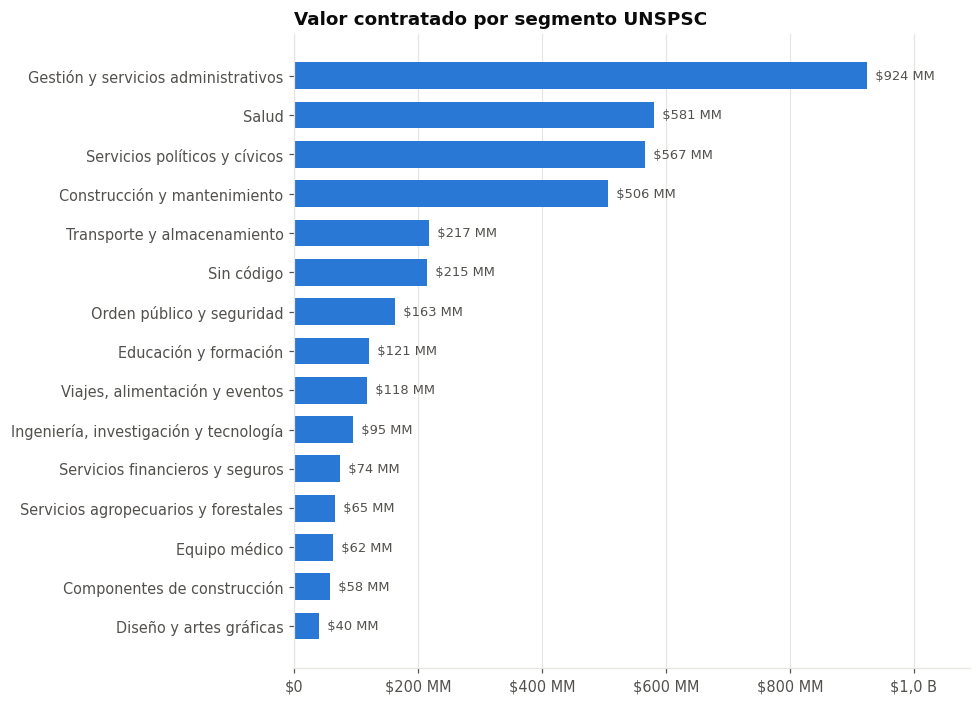

segmento,n_contratos,valor_total,valor_mediano,pct_contratos,pct_valor
Gestión y servicios administrativos,27.031,"$923,8 mil millones","$15,6 millones","59,3 %","21,4 %"
Salud,9.365,"$581,0 mil millones","$12,0 millones","20,6 %","13,5 %"
Servicios políticos y cívicos,1.577,"$566,8 mil millones","$20,0 millones","3,5 %","13,1 %"
Construcción y mantenimiento,662,"$506,1 mil millones","$44,9 millones","1,5 %","11,7 %"
Transporte y almacenamiento,381,"$217,4 mil millones","$39,9 millones","0,8 %","5,0 %"
Sin código,559,"$214,8 mil millones","$254,6 millones","1,2 %","5,0 %"
Orden público y seguridad,131,"$162,8 mil millones","$70,0 millones","0,3 %","3,8 %"
Educación y formación,168,"$121,0 mil millones","$64,8 millones","0,4 %","2,8 %"
"Viajes, alimentación y eventos",563,"$117,7 mil millones","$39,0 millones","1,2 %","2,7 %"
"Ingeniería, investigación y tecnología",564,"$94,6 mil millones","$25,9 millones","1,2 %","2,2 %"


In [13]:
seg = resumen_por(det, "segmento")
barras(seg.set_index("segmento")["valor_total"], "Valor contratado por segmento UNSPSC")
mostrar(seg.head(15), pesos=["valor_total", "valor_mediano"], pct=["pct_contratos", "pct_valor"])

### 6.5 Quién compra: entidades

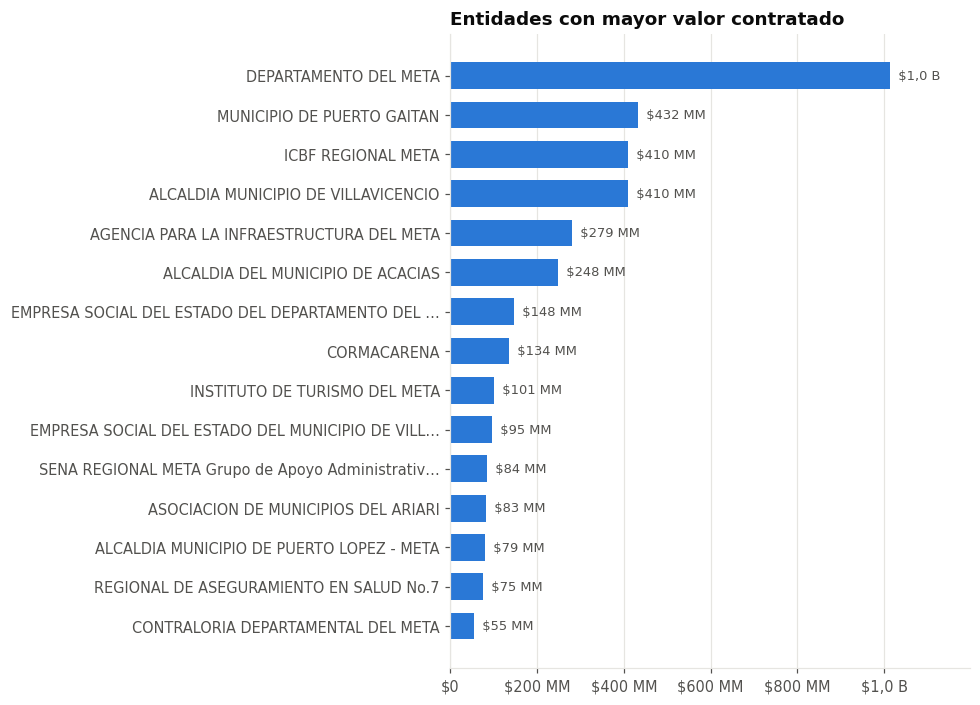

nombre_entidad,n_contratos,valor_total,pct_directa,proveedores,pct_con_adicion
DEPARTAMENTO DEL META,4.939,"$1,01 billones","88,0 %",2.206,"12,4 %"
MUNICIPIO DE PUERTO GAITAN,1.721,"$432,3 mil millones","90,6 %",817,"4,1 %"
ICBF REGIONAL META,647,"$410,4 mil millones","50,5 %",339,"21,9 %"
ALCALDIA MUNICIPIO DE VILLAVICENCIO,5.969,"$410,1 mil millones","92,2 %",2.761,"8,0 %"
AGENCIA PARA LA INFRAESTRUCTURA DEL META,1.207,"$279,1 mil millones","95,8 %",554,"14,2 %"
ALCALDIA DEL MUNICIPIO DE ACACIAS,2.136,"$248,4 mil millones","92,6 %",866,"14,8 %"
EMPRESA SOCIAL DEL ESTADO DEL DEPARTAMENTO DEL META E.S.E,4.945,"$147,6 mil millones","0,0 %",2.294,"22,6 %"
CORMACARENA,3.158,"$133,9 mil millones","96,0 %",1.133,"11,2 %"
INSTITUTO DE TURISMO DEL META,1.421,"$100,8 mil millones","92,8 %",616,"2,9 %"
EMPRESA SOCIAL DEL ESTADO DEL MUNICIPIO DE VILLAVICENCIO,2.039,"$94,7 mil millones","0,0 %",1.055,"4,4 %"


In [14]:
ent = (det.groupby("nombre_entidad")
          .agg(n_contratos=("id_contrato", "size"), valor_total=("valor_del_contrato", "sum"),
               pct_directa=("es_directa", "mean"), proveedores=("proveedor_id", "nunique"),
               pct_con_adicion=("tiene_adicion", "mean"))
          .sort_values("valor_total", ascending=False))
ent[["pct_directa", "pct_con_adicion"]] *= 100
barras(ent["valor_total"], "Entidades con mayor valor contratado")
mostrar(ent.head(20).reset_index(), pesos=["valor_total"], pct=["pct_directa", "pct_con_adicion"])

### 6.6 Quién vende: proveedores y concentración

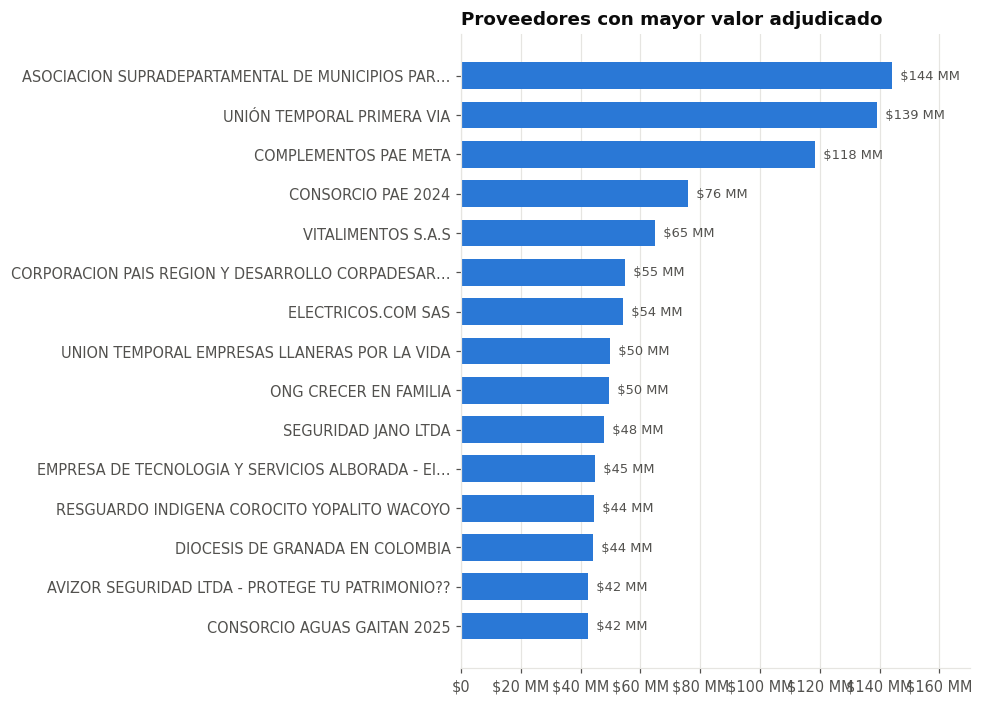

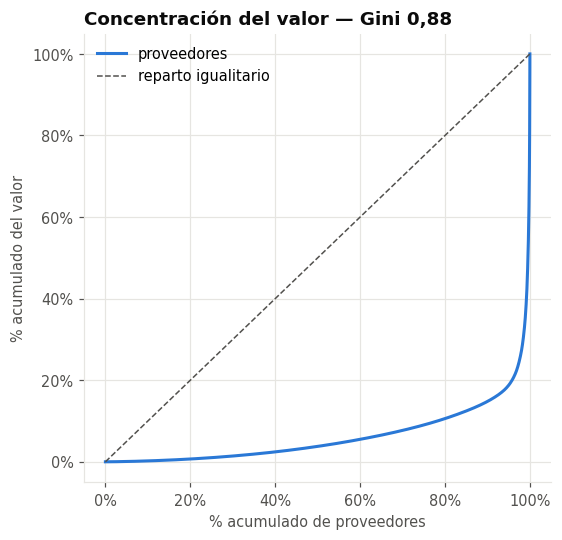

Los 10 proveedores más grandes reciben el 18,5 % del valor.


In [15]:
prov = (det.groupby("proveedor_id")
           .agg(proveedor=("proveedor_adjudicado", "first"), n_contratos=("id_contrato", "size"),
                valor_total=("valor_del_contrato", "sum"), entidades=("nombre_entidad", "nunique"),
                es_pyme=("es_pyme", "max"))
           .sort_values("valor_total", ascending=False))
barras(prov.set_index("proveedor")["valor_total"], "Proveedores con mayor valor adjudicado")

def gini(x):
    x = np.sort(np.asarray(x, float))
    if len(x) == 0 or x.sum() == 0: return np.nan
    c = np.cumsum(x)
    return (len(x) + 1 - 2 * c.sum() / c[-1]) / len(x)

# Curva de Lorenz del valor por proveedor
x = np.sort(prov["valor_total"].values)
lor = np.insert(np.cumsum(x) / x.sum(), 0, 0)
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot(np.linspace(0, 1, len(lor)), lor, color=AZUL, lw=2, label="proveedores")
ax.plot([0, 1], [0, 1], color=TINTA2, lw=1, ls="--", label="reparto igualitario")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("% acumulado de proveedores"); ax.set_ylabel("% acumulado del valor")
ax.set_title(f"Concentración del valor — Gini {_es(f'{gini(x):.2f}')}")
ax.legend(); plt.tight_layout(); plt.show()

top10 = prov["valor_total"].head(10).sum() / prov["valor_total"].sum() * 100
print(f"Los 10 proveedores más grandes reciben el {pct(top10)} del valor.")

In [16]:
# Concentración dentro de cada entidad: índice Herfindahl-Hirschman (0–10.000)
# > 2.500 indica que pocos proveedores reciben casi todo el valor de esa entidad
def hhi(g):
    s = g.groupby("proveedor_id")["valor_del_contrato"].sum()
    return ((s / s.sum() * 100) ** 2).sum()

grandes = ent.index[ent["n_contratos"] >= MIN_CONTRATOS_ENTIDAD]
hhi_ent = (det[det["nombre_entidad"].isin(grandes)]
             .groupby("nombre_entidad").apply(hhi, include_groups=False)
             .rename("hhi").to_frame().join(ent[["n_contratos", "valor_total", "proveedores"]])
             .sort_values("hhi", ascending=False))
print(f"Entidades con HHI > 2.500: {(hhi_ent['hhi'] > 2500).sum()} de {len(hhi_ent)}")
mostrar(hhi_ent.head(15).reset_index(), pesos=["valor_total"])

Entidades con HHI > 2.500: 4 de 59


nombre_entidad,hhi,n_contratos,valor_total,proveedores
CONTRALORIA DEPARTAMENTAL DEL META,9.541,33,"$55,2 mil millones",20
ESECU,4.457,31,"$2,8 mil millones",30
LOTERIA DEL META,3.953,49,"$4,0 mil millones",30
AGENCIA PARA LA INFRAESTRUCTURA DEL META,2.631,1.207,"$279,1 mil millones",554
ASMETA,2.398,130,"$37,7 mil millones",89
FISCALÍA GENERAL DE LA NACIÓN REGIONAL ORINOQUÍA,2.274,69,"$47,0 mil millones",55
COLONIA AGRICOLA ACACIAS,1.772,77,"$2,0 mil millones",24
ESTABLECIMIENTO PENITENCIARIO DE MEDIANA SEGURIDAD Y CARCELARIO DE VILLAVICENCIO,1.707,82,"$3,8 mil millones",22
Asociacion de Municipios y Esquema Asociativo Territorial denominado Desarrollo Sostenible y Equidad Territorial,1.677,31,"$35,8 mil millones",29
ASOCIACION DE MUNICIPIOS DEL ARIARI,1.510,137,"$83,0 mil millones",87


### 6.7 Pymes

,n,valor,pct_n,pct_valor
es_pyme,,,,
No pyme,38.891,"$2,66 billones",85.4 %,61.6 %
Pyme,6.663,"$1,66 billones",14.6 %,38.4 %


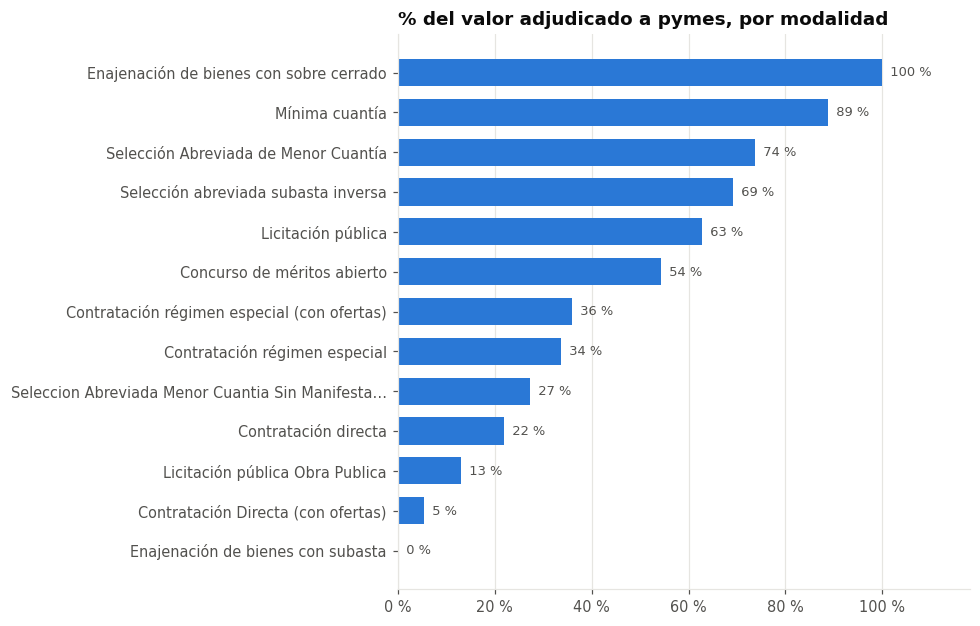

In [17]:
pyme = det.groupby("es_pyme", dropna=False).agg(n=("id_contrato", "size"), valor=("valor_del_contrato", "sum"))
pyme["pct_n"] = pyme["n"] / pyme["n"].sum() * 100
pyme["pct_valor"] = pyme["valor"] / pyme["valor"].sum() * 100
display(pyme.rename(index={True: "Pyme", False: "No pyme"}).style.format(
    {"n": entero, "valor": cop, "pct_n": "{:.1f} %", "pct_valor": "{:.1f} %"}, na_rep="—"))

pyme_mod = (det.groupby("modalidad_de_contratacion")
               .apply(lambda g: g.loc[g["es_pyme"] == True, "valor_del_contrato"].sum() / g["valor_del_contrato"].sum() * 100,
                      include_groups=False)
               .sort_values(ascending=False))
barras(pyme_mod, "% del valor adjudicado a pymes, por modalidad", fmt=lambda v, _=None: f"{v:.0f} %")

### 6.8 Plazos, adiciones y ejecución

In [18]:
plazos = (det.groupby("tipo_de_contrato")
             .agg(n=("id_contrato", "size"),
                  duracion_mediana_dias=("duracion_dias", "median"),
                  pct_con_adicion=("tiene_adicion", "mean"),
                  dias_adicionados_mediana=("dias_adicionados", lambda s: s[s > 0].median()),
                  pct_pagado_mediano=("pct_pagado", "median"))
             .sort_values("n", ascending=False))
plazos[["pct_con_adicion", "pct_pagado_mediano"]] *= 100
mostrar(plazos.head(12).reset_index(), pct=["pct_con_adicion", "pct_pagado_mediano"])

tipo_de_contrato,n,duracion_mediana_dias,pct_con_adicion,dias_adicionados_mediana,pct_pagado_mediano
Prestación de servicios,38.921,117,"10,8 %",49,"100,0 %"
Decreto 092 de 2017,2.939,97,"7,8 %",60,"100,0 %"
Otro,1.086,185,"25,5 %",62,"0,0 %"
Suministros,1.056,123,"11,0 %",38,"96,3 %"
Compraventa,649,28,"14,5 %",30,"100,0 %"
Obra,398,108,"41,5 %",75,"100,0 %"
Arrendamiento de inmuebles,218,246,"39,0 %",100,"80,3 %"
Consultoría,85,90,"35,3 %",62,"52,4 %"
Seguros,84,283,"17,9 %",68,"98,9 %"
Interventoría,78,210,"44,9 %",92,"45,7 %"


In [19]:
# Ejecución financiera por año de firma: los contratos recientes siempre aparecen menos pagados
ejec = det.groupby("anio").apply(lambda g: g["valor_pagado"].sum() / g["valor_del_contrato"].sum() * 100,
                                 include_groups=False)
estado = resumen_por(det, "estado_contrato")
print("Valor pagado / valor contratado por año:", " | ".join(f"{int(a)}: {pct(p)}" for a, p in ejec.items()))
mostrar(estado, pesos=["valor_total", "valor_mediano"], pct=["pct_contratos", "pct_valor"])

Valor pagado / valor contratado por año: 2024: 52,9 % | 2025: 59,7 %


estado_contrato,n_contratos,valor_total,valor_mediano,pct_contratos,pct_valor
Modificado,5.641,"$1,53 billones","$27,0 millones","12,4 %","35,4 %"
terminado,14.991,"$1,41 billones","$15,6 millones","32,9 %","32,8 %"
En ejecución,11.321,"$766,7 mil millones","$13,4 millones","24,9 %","17,8 %"
Cerrado,13.385,"$387,3 mil millones","$15,0 millones","29,4 %","9,0 %"
Suspendido,59,"$214,5 mil millones","$143,8 millones","0,1 %","5,0 %"
Aprobado,86,"$3,0 mil millones","$10,5 millones","0,2 %","0,1 %"
cedido,71,"$1,6 mil millones","$21,2 millones","0,2 %","0,0 %"


### 6.9 Búsqueda por tema en el objeto del contrato

Escribe palabras separadas por `|` (sin tildes). Ejemplo para agua y saneamiento.

In [20]:
def buscar(patron, df=None, top=10):
    df = det if df is None else df
    patron = unicodedata.normalize("NFKD", patron).encode("ascii", "ignore").decode().lower()
    sub = df[df["objeto_norm"].str.contains(patron, regex=True, na=False)]
    print(f"'{patron}': {entero(len(sub))} contratos ({pct(len(sub)/len(df)*100)}) por {cop(sub['valor_del_contrato'].sum())}")
    tabla = (sub.groupby("nombre_entidad")
                .agg(n_contratos=("id_contrato", "size"), valor_total=("valor_del_contrato", "sum"))
                .sort_values("valor_total", ascending=False).head(top))
    display(mostrar(tabla.reset_index(), pesos=["valor_total"]))
    return sub

agua = buscar(r"acueducto|alcantarillado|agua potable|riego|saneamiento|cuenca|hidric")
agua.sort_values("valor_del_contrato", ascending=False)[
    ["fecha_de_firma", "nombre_entidad", "proveedor_adjudicado", "valor_del_contrato", "objeto_del_contrato"]].head(10)

'acueducto|alcantarillado|agua potable|riego|saneamiento|cuenca|hidric': 801 contratos (1,8 %) por $158,1 mil millones


nombre_entidad,n_contratos,valor_total
MUNICIPIO DE PUERTO GAITAN,56,"$71,1 mil millones"
ALCALDIA DEL MUNICIPIO DE ACACIAS,22,"$23,8 mil millones"
ALCALDIA MUNICIPIO DE VILLAVICENCIO,185,"$14,2 mil millones"
ALCALDIA MUNICIPIO DE PUERTO LOPEZ - META,12,"$13,4 mil millones"
CORMACARENA,136,"$11,3 mil millones"
ASOCIACION DE MUNICIPIOS DEL ARIARI,3,"$4,7 mil millones"
DEPARTAMENTO DEL META,206,"$4,1 mil millones"
ALCALDIA DE SAN MARTIN  META,4,"$3,8 mil millones"
SUBCUENTA PARA LA ADMON DE LOS RECURSOS Y MANEJO SPN FONAM - DTOR,53,"$2,7 mil millones"
ALCALDIA MUNICIPIO DE CUMARAL META,5,"$1,7 mil millones"


,fecha_de_firma,nombre_entidad,proveedor_adjudicado,valor_del_contrato,objeto_del_contrato
33968,2025-07-17,MUNICIPIO DE PUERTO GAITAN,CONSORCIO AGUAS GAITAN 2025,4.240890e+10,CONSTRUCCIÓN SISTEMAS DE ACUEDUCTOS PARA LOS RESGUARDOS INDÍGENAS WACOYO; AW...
24888,2025-02-13,ALCALDIA DEL MUNICIPIO DE ACACIAS,EMPRESA DE SERVICIOS PUBLICOS DE ACACIAS,5.695271e+09,SUBSIDIOS PARA LA VIGENCIA 2025 A LOS USUARIOS DE LOS SERVICIOS PÚBLICOS DE ...
20202,2024-12-28,MUNICIPIO DE PUERTO GAITAN,Asociacion de Municipios y Esquema Asociativo Territorial denominado Desarro...,5.620000e+09,FORTALECIMIENTO DE ACCIONES PARA EL SANEAMIENTO Y LEGALIZACIÓN DE LOS ASENTA...
3369,2024-02-23,ALCALDIA DEL MUNICIPIO DE ACACIAS,EMPRESA DE SERVICIOS PUBLICOS DE ACACIAS,5.015328e+09,SUBSIDIOS PARA LA VIGENCIA 2024 A LOS USUARIOS DE LOS SERVICIOS PUBLICOS DE ...
41297,2025-10-17,MUNICIPIO DE PUERTO GAITAN,PERLA ESP - PROVEEDOR,4.717908e+09,AUNAR ESFUERZOS PARA EL FORTALECIMIENTO DE ESQUEMAS ORGANIZACIONALES PARA OP...
43101,2025-11-07,ALCALDIA DEL MUNICIPIO DE ACACIAS,EMPRESA DE SERVICIOS PUBLICOS DE ACACIAS,4.644248e+09,SUBSIDIOS PARA LA VIGENCIA 2026 A LOS USUARIOS DE LOS SERVICIOS PUBLICOS DE ...
3288,2024-02-22,ALCALDIA DEL MUNICIPIO DE ACACIAS,EMPRESA DE SERVICIOS PUBLICOS DE ACACIAS,4.579619e+09,SUBSIDIOS PARA LA VIGENCIA 2024 A LOS USUARIOS DE LOS SERVICIOS PUBLICOS DE ...
43920,2025-11-24,ASOCIACION DE MUNICIPIOS DEL ARIARI,PROSPECTIVA DE PROYECTOS S.A.S,4.202092e+09,DESARROLLAR LAS ACTIVIDADES Y ACCIONES CORRESPONDIENTES AL IMPULSO A NEGOCIO...
34995,2025-07-31,CORMACARENA,MASBOSQUES,3.667048e+09,AUNAR ESFUERZOS ADMINISTRATIVOS; TÉCNICOS; FINANCIEROS Y JURÍDICOS; PARA LA ...
39723,2025-09-26,ALCALDIA MUNICIPIO DE PUERTO LOPEZ - META,EMPRESA DE SERVICIOS PÚBLICOS DE PUERTO LÓPEZ SA ESP,2.975468e+09,AUNAR ESFUERZOS TÉCNICOS; ADMINISTRATIVOS Y FINANCIEROS ENTRE EL MUNICIPIO D...


### 6.10 Señales de alerta

Son **señales para priorizar revisión**, no evidencia de irregularidad: muchas tienen explicaciones legítimas (convenios interadministrativos, prestación de servicios recurrente, urgencias). Cada contrato suma un punto por señal.

In [21]:
p99_directa = det.loc[det["es_directa"], "valor_del_contrato"].quantile(0.99)
recurrencia = det.groupby(["nombre_entidad", "proveedor_id", "anio"])["id_contrato"].transform("size")

senales = pd.DataFrame({
    "directa_valor_alto":      det["es_directa"] & (det["valor_del_contrato"] >= p99_directa),
    "proveedor_recurrente":    recurrencia >= MIN_CONTRATOS_RECURRENTE,
    "adicion_mayor_al_plazo":  det["dias_adicionados"].fillna(0) > det["duracion_dias"].clip(lower=1),
    "firma_ultima_quincena":   (det["fecha_de_firma"].dt.month == 12) & (det["fecha_de_firma"].dt.day >= 15),
    "inicio_antes_de_firma":   det["q_inicio_antes_de_firma"],
}, index=det.index).fillna(False)

det["n_senales"] = senales.sum(axis=1)
det["senales"] = senales.apply(lambda r: ", ".join(c for c, v in r.items() if v), axis=1)

print(f"Umbral de 'directa de valor alto' (p99 de la contratación directa): {cop(p99_directa)}")
display(senales.mean().mul(100).rename("% de contratos").to_frame().style.format("{:.2f} %"))

alertas = (det[det["n_senales"] >= 2]
             .sort_values(["n_senales", "valor_del_contrato"], ascending=False)
             [["n_senales", "senales", "fecha_de_firma", "nombre_entidad", "proveedor_adjudicado",
               "modalidad_de_contratacion", "valor_del_contrato", "dias_adicionados",
               "objeto_del_contrato", "urlproceso"]])
print(f"Contratos con 2 o más señales: {entero(len(alertas))}")
alertas.head(20)

Umbral de 'directa de valor alto' (p99 de la contratación directa): $400,0 millones


,% de contratos
directa_valor_alto,0.66 %
proveedor_recurrente,0.69 %
adicion_mayor_al_plazo,0.07 %
firma_ultima_quincena,2.12 %
inicio_antes_de_firma,0.04 %


Contratos con 2 o más señales: 95


,n_senales,senales,fecha_de_firma,nombre_entidad,proveedor_adjudicado,modalidad_de_contratacion,valor_del_contrato,dias_adicionados,objeto_del_contrato,urlproceso
19860,3,"directa_valor_alto, proveedor_recurrente, firma_ultima_quincena",2024-12-16,ALCALDIA MUNICIPIO DE VILLAVICENCIO,EMPRESA DE TECNOLOGIA Y SERVICIOS ALBORADA - EICE- PROVEEDOR,Contratación directa,1.040000e+09,0,PRESTACION DE SERVICIOS DE TOMA DE INFORMACION PARA EL FORTALECIMIENTO MEDIA...,https://community.secop.gov.co/Public/Tendering/OpportunityDetail/Index?noti...
19937,3,"directa_valor_alto, proveedor_recurrente, firma_ultima_quincena",2024-12-18,ALCALDIA MUNICIPIO DE VILLAVICENCIO,EMPRESA DE TECNOLOGIA Y SERVICIOS ALBORADA - EICE- PROVEEDOR,Contratación directa,4.324300e+08,0,PRESTACIÓN DE SERVICIOS INTEGRALES E IMPLEMENTACIÓN DE NUEVAS TECNOLOGÍAS PA...,https://community.secop.gov.co/Public/Tendering/OpportunityDetail/Index?noti...
43137,2,"directa_valor_alto, proveedor_recurrente",2025-11-07,ALCALDIA MUNICIPIO DE VILLAVICENCIO,EMPRESA DE TECNOLOGIA Y SERVICIOS ALBORADA - EICE- PROVEEDOR,Contratación directa,7.800000e+09,92,PRESTACIÓN DE SERVICIOS PARA LA OPERACIÓN Y MODERNIZACIÓN CONTINUA DEL COMPO...,https://community.secop.gov.co/Public/Tendering/OpportunityDetail/Index?noti...
45476,2,"directa_valor_alto, firma_ultima_quincena",2025-12-30,Asociacion de Municipios y Esquema Asociativo Territorial denominado Desarro...,DACA INGENIERIA SAS,Contratación directa,6.630455e+09,120,MEJORAMIENTO DE LA INFRAESTRUCTURA VIAL EN ZONA URBANA Y RURAL DEL MUNICIPIO...,https://community.secop.gov.co/Public/Tendering/OpportunityDetail/Index?noti...
20202,2,"directa_valor_alto, firma_ultima_quincena",2024-12-28,MUNICIPIO DE PUERTO GAITAN,Asociacion de Municipios y Esquema Asociativo Territorial denominado Desarro...,Contratación directa,5.620000e+09,273,FORTALECIMIENTO DE ACCIONES PARA EL SANEAMIENTO Y LEGALIZACIÓN DE LOS ASENTA...,https://community.secop.gov.co/Public/Tendering/OpportunityDetail/Index?noti...
41297,2,"directa_valor_alto, proveedor_recurrente",2025-10-17,MUNICIPIO DE PUERTO GAITAN,PERLA ESP - PROVEEDOR,Contratación directa,4.717908e+09,122,AUNAR ESFUERZOS PARA EL FORTALECIMIENTO DE ESQUEMAS ORGANIZACIONALES PARA OP...,https://community.secop.gov.co/Public/Tendering/OpportunityDetail/Index?noti...
2811,2,"directa_valor_alto, proveedor_recurrente",2024-02-15,ALCALDIA MUNICIPIO DE VILLAVICENCIO,EMPRESA DE TECNOLOGIA Y SERVICIOS ALBORADA - EICE- PROVEEDOR,Contratación directa,4.301702e+09,14,PRESTACIÓN DE SERVICIOS INTEGRALES E IMPLEMENTACIÓN DE NUEVAS TECNOLOGÍAS PA...,https://community.secop.gov.co/Public/Tendering/OpportunityDetail/Index?noti...
45210,2,"directa_valor_alto, firma_ultima_quincena",2025-12-18,REGIONAL DE ASEGURAMIENTO EN SALUD No.7,HOSPITAL DEPARTAMENTAL DE VILLAVICENCIO ESE,Contratación Directa (con ofertas),4.296344e+09,61,PRESTACION DE SERVICIOS DE SALUD DE BAJA; MEDIANA Y ALTA COMPLEJIDAD EN SERV...,https://community.secop.gov.co/Public/Tendering/OpportunityDetail/Index?noti...
21012,2,"directa_valor_alto, proveedor_recurrente",2025-01-09,ALCALDIA MUNICIPIO DE VILLAVICENCIO,EMPRESA DE TECNOLOGIA Y SERVICIOS ALBORADA - EICE- PROVEEDOR,Contratación directa,4.000000e+09,31,PRESTACIÓN DE SERVICIOS INTEGRALES E IMPLEMENTACIÓN DE NUEVAS TECNOLOGÍAS PA...,https://community.secop.gov.co/Public/Tendering/OpportunityDetail/Index?noti...
11755,2,"directa_valor_alto, adicion_mayor_al_plazo",2024-08-26,CORMACARENA,MASBOSQUES,Contratación directa,3.454952e+09,469,AUNAR ESFUERZOS ADMINISTRATIVOS; TÉCNICOS; FINANCIEROS Y JURÍDICOS; PARA LA ...,https://community.secop.gov.co/Public/Tendering/OpportunityDetail/Index?noti...


## 7. Exportar resultados

In [ ]:
salida = DATA / f"resultados_secop_{etiqueta}_{FECHA_INI}_{FECHA_FIN}.xlsx"
quitar_tz = lambda d: d.assign(**{c: d[c].dt.tz_localize(None) for c in d.select_dtypes("datetimetz")})

with pd.ExcelWriter(salida, engine="openpyxl") as xls:
    nac_dep.to_excel(xls, sheet_name="pais_departamentos", index=False)
    nac_mes.to_excel(xls, sheet_name="pais_mensual", index=False)
    nac_mod.to_excel(xls, sheet_name="pais_modalidad", index=False)
    nac_tipo.to_excel(xls, sheet_name="pais_tipo", index=False)
    mod.to_excel(xls, sheet_name="modalidad", index=False)
    tipo.to_excel(xls, sheet_name="tipo_contrato", index=False)
    seg.to_excel(xls, sheet_name="segmentos_unspsc", index=False)
    ent.reset_index().to_excel(xls, sheet_name="entidades", index=False)
    prov.reset_index().head(5000).to_excel(xls, sheet_name="proveedores", index=False)
    hhi_ent.reset_index().to_excel(xls, sheet_name="concentracion_hhi", index=False)
    plazos.reset_index().to_excel(xls, sheet_name="plazos_adiciones", index=False)
    quitar_tz(alertas).head(20000).to_excel(xls, sheet_name="alertas", index=False)
print(f"Resultados guardados en {salida}")